# DupCaller manuscript figures

Generates every Python-made plot in **manuscript order** (main_v8 Figures 2–6, then supplementary_figures_v8 S1–S6)
and saves each one under `DupCaller_manuscript_plots/` named by its figure/panel number.

Panels drawn outside Python (schematics, Fig. 1, 2a, 3a, 3b/e, 3d/g, 4c, 5c, 6c/d mutational spectra)
and supplementary S2a, S5 (spectra) and S7 are not generated here.

Each figure section resets the plotting style first, so any section can be re-run on its own and
the result doesn't depend on which cells ran before it.

| Output file | Manuscript panel | Data (`data/DupCaller_figure_data.xlsx` tab unless noted) |
|---|---|---|
| Figure2b_precision / Figure2b_recall | Fig 2b | downsampling |
| Figure2c | Fig 2c | downsampling |
| Figure2d | Fig 2d | downsampling |
| Figure3c_SBS_count / Figure3c_SBS_burden | Fig 3c | AA_neuron_cordblood |
| Figure3f_indel_count / Figure3f_indel_burden | Fig 3f | AA_neuron_cordblood |
| Figure4a, Figure4b, Figure4d | Fig 4a, b, d | AA_neuron_cordblood |
| Figure5a, Figure5b, Figure5d | Fig 5a, b, d | AA_neuron_cordblood |
| Figure6a, Figure6b | Fig 6a, b | sperm_blood_saliva |
| Supplementary/FigureS1 (+ FigureS1_S3_legend.svg) | Supp Fig S1 | synthetic_SBS_benchmark.xlsx |
| Supplementary/FigureS2b_precision / _recall / _F1 | Supp Fig S2b (SBS) | synthetic_SBS_summary |
| Supplementary/FigureS2c_precision / _recall / _F1 | Supp Fig S2c (indel) | synthetic_indel_summary |
| Supplementary/FigureS3 | Supp Fig S3 | synthetic_indel_benchmark.xlsx |
| Supplementary/FigureS4 | Supp Fig S4 | AA_neuron_cordblood |
| Supplementary/FigureS6 | Supp Fig S6 | runtime |
| SBS96_cosine_similarity.csv (table, not a plot) | Spectrum cosine similarities (Figs 3, 6; 2×2+ vs 2×2−) | source_data_spectra/DupCaller_SBS96_ID83_spectra.xlsx |

## Setup

In [53]:
import os, itertools, math, re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.ticker as mticker
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.markers as mmark
from scipy.stats import chi2, gamma

# ---- paths ---------------------------------------------------------------
# Everything is resolved relative to this folder, so the whole package can be moved/shared as is.
try:
    ROOT = os.path.dirname(os.path.abspath(__file__))     # running the .py script
except NameError:
    ROOT = os.getcwd()                                     # running the notebook (Jupyter starts in its folder)
DATA_DIR = os.path.join(ROOT, "data")
OUT_DIR  = os.path.join(ROOT, "DupCaller_manuscript_plots")
SUPP_DIR = os.path.join(OUT_DIR, "Supplementary")

FIGURE_DATA_XLSX    = os.path.join(DATA_DIR, "DupCaller_figure_data.xlsx")        # per-sample data, one tab per analysis
SYNTH_SBS_XLSX      = os.path.join(DATA_DIR, "synthetic_SBS_benchmark.xlsx")      # Fig S1: DupCaller PR curves + NanoSeq points
SYNTH_INDEL_XLSX    = os.path.join(DATA_DIR, "synthetic_indel_benchmark.xlsx")    # Fig S3: DupCaller PR curves + NanoSeq points
SPECTRA_XLSX        = os.path.join(DATA_DIR, "source_data_spectra", "DupCaller_SBS96_ID83_spectra.xlsx")  # SBS96 cosine similarities

missing = [f for f in [FIGURE_DATA_XLSX, SYNTH_SBS_XLSX, SYNTH_INDEL_XLSX, SPECTRA_XLSX] if not os.path.exists(f)]
if missing:
    print("WARNING - missing input files (dependent plots will be skipped):", *missing, sep="\n  ")

MAKE_SUPPLEMENTARY = True   # set False to only make main-text figures

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(SUPP_DIR, exist_ok=True)

# ---- load every supplementary table once ---------------------------------
data = pd.read_excel(FIGURE_DATA_XLSX, sheet_name=None, engine="openpyxl")
SYNTH_SBS    = data["synthetic_SBS_summary"]     # Fig S2b  (25 synthetic SBS datasets)
SYNTH_INDEL  = data["synthetic_indel_summary"]   # Fig S2c  (25 synthetic indel datasets)
COHORTS      = data["AA_neuron_cordblood"]       # Figs 3, 4, 5, S4 (per sample)
SPERM        = data["sperm_blood_saliva"]        # Fig 6 (per sample)
RUNTIME      = data["runtime"]                   # Fig S6 (per sample and step)
DOWNSAMPLING = data["downsampling"]              # Fig 2 (per downsampled dataset)
# Fig 4d: SBS calls per cord-blood sample, SBS96 channel and caller, with each channel's correction ratio
# (columns: Sample, Mutation Type, number, correction ratio, Caller — renamed by position)
CORD_CI = pd.read_excel(FIGURE_DATA_XLSX, "cordblood_CI_calculation", engine="openpyxl")
CORD_CI = CORD_CI.iloc[:, :5].set_axis(["Sample", "channel", "count", "ratio", "Caller"], axis=1)
_bad = CORD_CI[CORD_CI.isna().any(axis=1)]
_dup = CORD_CI[CORD_CI.duplicated()]
if len(_bad) or len(_dup):
    print(f"NOTE: cordblood_CI_calculation - ignoring {len(_bad)} incomplete and {len(_dup)} duplicated row(s) "
          f"(Excel rows {sorted(list(_bad.index + 2) + list(_dup.index + 2))})")
CORD_CI = CORD_CI.drop(_bad.index.union(_dup.index))

# AA_neuron_cordblood has trailing empty rows; cohort labels carry "(n=..)" in v5
COHORTS = COHORTS.dropna(subset=["cohort"]).copy()
COHORTS["cohort"] = COHORTS["cohort"].str.replace(r"\s*\(n=", " (n=", regex=True)   # "Neuron(n=17)" -> "Neuron (n=17)"
is_AA = COHORTS["cohort"].str.startswith("Aristolochic")
COHORTS_noAA = COHORTS[~is_AA].copy()
COHORTS_AA = COHORTS[is_AA].copy()
# 3 AA samples in table order (40uM-72h, 70uM-48h, 80uM-48h) -> AA_1..AA_3
AA_LABELS = [f"AA_{i+1}" for i in range(len(COHORTS_AA))]

In [54]:
FONT_SIZE = 8      # every piece of text on every plot
DPI = 600          # small physical size -> save at high resolution


def legend_case(text):
    """Capitalize the first letter of every word in legend text, leaving the rest of each word as is
    (keeps 'DupCaller', 'NanoSeq', 'SBS'); configuration labels such as 1×n / n×1 are left untouched."""
    def cap(word):
        if "\u00d7" in word or re.match(r"^[(\[]?n=", word):
            return word
        for i, ch in enumerate(word):
            if ch.isalpha():
                return word[:i] + ch.upper() + word[i + 1:]
        return word
    return re.sub(r"[^\s]+", lambda m: cap(m.group(0)), text)


def boldify(fig=None, max_ticks=5, **_ignored):
    """Final text pass: every label/title/tick/legend/annotation at FONT_SIZE pt bold,
    and at most `max_ticks` labelled ticks on numeric linear axes (log and categorical axes untouched)."""
    if fig is None:
        fig = plt.gcf()
    for ax in fig.get_axes():
        for axis in (ax.xaxis, ax.yaxis):
            if isinstance(axis.get_major_locator(), mticker.AutoLocator):
                axis.set_major_locator(mticker.MaxNLocator(nbins=max_ticks - 1, steps=[1, 2, 2.5, 5, 10], min_n_ticks=3))
        ax.tick_params(axis="both", which="both", labelsize=FONT_SIZE)
        for lbl in ax.get_xticklabels() + ax.get_yticklabels():
            lbl.set_fontweight("bold")
        ax.xaxis.get_offset_text().set_fontsize(FONT_SIZE)
        ax.yaxis.get_offset_text().set_fontsize(FONT_SIZE)
        for t in [ax.xaxis.label, ax.yaxis.label, ax.title] + list(ax.texts):
            t.set_fontsize(FONT_SIZE)
            t.set_fontweight("bold")
        leg = ax.get_legend()
        if leg is not None:
            for t in leg.get_texts() + [leg.get_title()]:
                t.set_text(legend_case(t.get_text()))
                t.set_fontsize(FONT_SIZE)
                t.set_fontweight("bold")


def savefig_tight(fig, path, dpi=DPI):
    """Save so bold labels and outside legends are never clipped."""
    extra = []
    for ax in fig.get_axes():
        extra += [ax.xaxis.label, ax.yaxis.label]
        if ax.get_legend() is not None:
            extra.append(ax.get_legend())
        extra += list(ax.texts)
    fig.savefig(path, dpi=dpi, bbox_inches='tight', bbox_extra_artists=extra, pad_inches=0.02)


def legend_overlaps(ax):
    """True if the axes' legend box covers any plotted point, line segment, bar or error bar."""
    leg = ax.get_legend()
    if leg is None:
        return False
    fig = ax.figure
    fig.canvas.draw()
    box = leg.get_window_extent().expanded(1.02, 1.04)
    ax_box = ax.get_window_extent()
    if not ax_box.overlaps(box):            # legend sits fully outside the axes
        return False
    for coll in ax.collections:             # scatter points, error-bar line collections
        offs = coll.get_offsets()
        if len(offs) and coll.get_transform() is not None:
            pts = coll.get_offset_transform().transform(offs)
            if np.any(box.contains_points(pts) if hasattr(box, "contains_points") else
                      [(box.x0 <= x <= box.x1) and (box.y0 <= y <= box.y1) for x, y in pts]):
                return True
        for path in getattr(coll, "get_paths", lambda: [])():
            if coll.get_offsets().size and len(coll.get_offsets()) > 1:
                continue
            v = coll.get_transform().transform(path.interpolated(20).vertices)
            if any((box.x0 <= x <= box.x1) and (box.y0 <= y <= box.y1) for x, y in v):
                return True
    for line in ax.lines:                   # data lines, error bars, diagonal reference lines
        xy = line.get_xydata()
        if len(xy) == 0:
            continue
        xy = np.array(xy, float)
        if ax.get_xscale() == "log":        # 0 on a log axis -> just below the visible range
            xy[:, 0] = np.clip(xy[:, 0], ax.get_xlim()[0] / 100, None)
        if ax.get_yscale() == "log":
            xy[:, 1] = np.clip(xy[:, 1], ax.get_ylim()[0] / 100, None)
        xy = xy[np.isfinite(xy).all(axis=1)]
        v = line.get_transform().transform(xy)
        if len(v) > 1:                      # densify in display space so crossings are caught
            v = np.vstack([np.linspace(v[i], v[i + 1], 200) for i in range(len(v) - 1)])
        v = v[(v[:, 0] >= ax_box.x0) & (v[:, 0] <= ax_box.x1) & (v[:, 1] >= ax_box.y0) & (v[:, 1] <= ax_box.y1)]
        if any((box.x0 <= x <= box.x1) and (box.y0 <= y <= box.y1) for x, y in v):
            return True
    for patch in ax.patches:                # bars
        if patch.get_window_extent().overlaps(box) and patch.get_height() != 0:
            return True
    return False


LEGEND_SPOTS = ["upper left", "upper right", "lower right", "lower left",
                "center right", "center left", "upper center", "lower center"]


def fix_legend(ax, name=""):
    """If the legend covers data, move it to the first free corner/edge inside the axes;
    if none is free, put it just outside the axes on the right."""
    if not legend_overlaps(ax):
        return
    for loc in LEGEND_SPOTS:
        sns.move_legend(ax, loc, frameon=True)
        if not legend_overlaps(ax):
            print(f"  legend moved to '{loc}' in {name}")
            break
    else:
        sns.move_legend(ax, "upper left", bbox_to_anchor=(1.02, 1.0), frameon=False)
        print(f"  legend moved outside (right) in {name}")
    for t in ax.get_legend().get_texts() + [ax.get_legend().get_title()]:
        t.set_fontsize(FONT_SIZE); t.set_fontweight("bold")
    if legend_overlaps(ax):
        print(f"WARNING: legend still overlaps plot elements in {name}")


def save(fig, name, supp=False, dpi=DPI):
    """Save into DupCaller_manuscript_plots/ (or /Supplementary) and close."""
    for ax in fig.get_axes():
        fix_legend(ax, name)
    path = os.path.join(SUPP_DIR if supp else OUT_DIR, name)
    savefig_tight(fig, path, dpi=dpi)
    print("saved", os.path.relpath(path, ROOT))
    plt.close(fig)


# rc settings sized for print at FONT_SIZE (sizes in points)
PRINT_RC = {
    "font.size": FONT_SIZE, "axes.titlesize": FONT_SIZE, "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE, "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE, "legend.title_fontsize": FONT_SIZE,
    "font.weight": "bold", "axes.labelweight": "bold", "axes.titleweight": "bold",
    "axes.linewidth": 0.6, "lines.linewidth": 1.0, "lines.markersize": 3.5,
    "patch.linewidth": 0.5, "errorbar.capsize": 2,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3, "xtick.minor.size": 1.5, "ytick.minor.size": 1.5,
    "xtick.major.pad": 2, "ytick.major.pad": 2, "axes.labelpad": 2, "axes.titlepad": 4,
    "legend.handlelength": 1.2, "legend.handletextpad": 0.4, "legend.borderaxespad": 0.3,
    "legend.labelspacing": 0.3, "legend.borderpad": 0.3,
    "axes.formatter.use_mathtext": True,     # axis multipliers drawn as ×10ⁿ instead of 1e-n
    # one typeface everywhere, Arial Bold (incl. the ×10ⁿ multipliers, drawn in the regular text font)
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "mathtext.default": "regular",
    "svg.fonttype": "path",                  # SVG text drawn as Arial outlines, independent of the viewer's fonts
}
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # fallbacks are reported once below instead


def register_arial():
    """Make Arial / Arial Bold available to matplotlib and return True if it is.
    Looks in the system fonts first, then $ARIAL_FONT_DIR, ./fonts, and the Arial copy bundled with
    sigProfilerPlotting (if installed). Arial is not redistributed with this repository."""
    from matplotlib import font_manager
    import importlib.util

    def have_arial_bold():
        path = font_manager.findfont(font_manager.FontProperties(family="Arial", weight="bold"))
        return os.path.basename(path).lower().startswith("arial")

    if have_arial_bold():
        return True
    dirs = [os.environ.get("ARIAL_FONT_DIR"), os.path.join(ROOT, "fonts")]
    try:
        spec = importlib.util.find_spec("sigProfilerPlotting")
        if spec is not None and spec.origin:
            dirs.append(os.path.join(os.path.dirname(spec.origin), "fonts"))
    except (ImportError, ValueError):
        pass
    for d in dirs:
        if d and os.path.isdir(d):
            for fn in os.listdir(d):
                if fn.lower().startswith("arial") and fn.lower().endswith(".ttf"):
                    font_manager.fontManager.addfont(os.path.join(d, fn))
    return have_arial_bold()


if not register_arial():
    print("WARNING: Arial Bold not found - figures fall back to another sans-serif font. "
          "Install Arial or set ARIAL_FONT_DIR to a folder holding Arial.ttf and 'Arial Bold.ttf'.")


def set_style(theme=True, **_ignored):
    """Reset matplotlib, apply the seaborn 'ticks' theme (if used originally), then the print-size rc."""
    plt.rcdefaults()
    if theme:
        sns.set_theme(style="ticks", rc={"axes.spines.right": False, "axes.spines.top": False})
    plt.rcParams.update(PRINT_RC)


def poisson_ci(count, confidence=0.95):
    alpha = 1 - confidence
    lower = chi2.ppf(alpha/2, 2*count)/2 if count > 0 else 0.0
    upper = chi2.ppf(1-alpha/2, 2*(count+1))/2
    return lower, upper


def fay_feuer_ci(counts, weights, alpha=0.05):
    """95% CI for a weighted sum of Poisson counts (Fay & Feuer 1997), as in Methods:
    y = sum(w*n), v = sum(w^2*n), w_max = max(w); lower = Gamma(y^2/v, v/y) quantile alpha/2,
    upper = Gamma((y+w_max)^2/(v+w_max^2), (v+w_max^2)/(y+w_max)) quantile 1-alpha/2."""
    counts, weights = np.asarray(counts, float), np.asarray(weights, float)
    y, v, wmax = (weights * counts).sum(), (weights ** 2 * counts).sum(), weights.max()
    lower = gamma.ppf(alpha / 2, a=y * y / v, scale=v / y) if y > 0 else 0.0
    upper = gamma.ppf(1 - alpha / 2, a=(y + wmax) ** 2 / (v + wmax ** 2), scale=(v + wmax ** 2) / (y + wmax))
    return y, lower, upper


def strip_n(label):
    """'Neuron (n=17)' -> 'Neuron' (Fig 4b/5b legends show cohort names only)."""
    return re.sub(r"\s*\(n=\d+\)", "", label)


FAMILY_ORDER = ["1x1", "1x2", "2x1", "1xn", "nx1"]                      # values as stored in downsampling
FAMILY_LABEL = {k: k.replace("x", "\u00d7") for k in FAMILY_ORDER}      # display: 1×1, 1×2, 2×1, 1×n, n×1
FAMILY_LABEL_ORDER = [FAMILY_LABEL[k] for k in FAMILY_ORDER]
# Colours borrowed from Nature-family figure palettes:
#  * Fig 2b read-family configurations use the Nature Publishing Group palette (as in ggsci "npg"),
#    which already contains matched light/dark pairs. Grey for 1×1; each mirrored pair shares a hue
#    (light = 1×2 / 1×n, dark = 2×1 / n×1): NPG mint/teal and NPG tan/brown.
FAMILY_PALETTE = dict(zip(FAMILY_LABEL_ORDER, ["#9E9E9E",              # 1×1
                                               "#91D1C2", "#00A087",   # 1×2 / 2×1  (NPG mint / teal)
                                               "#B09C85", "#7E6148"])) # 1×n / n×1  (NPG tan / brown)
#  * Fig 2c–d mutation type uses the colour-blind-safe Wong palette (Nature Methods 8:441, 2011):
#    reddish purple for SBS, orange for indel - distinct from the red/blue (DupCaller/NanoSeq) used elsewhere.
MUTTYPE_LABEL = {"sbs": "SBS", "indel": "Indel"}      # Fig 2 text: first letter of every word capitalized
MUTTYPE_ORDER = ["SBS", "Indel"]
MUTTYPE_PALETTE = {"SBS": "#CC79A7", "Indel": "#E69F00"}
CORDBLOOD_SAMPLES = ["PD48442_NS_1", "PD48442_NS_2", "PD48442_NS_3", "PD48442_NS_4", "PD48442_NS_5", "PD48442_NS_7"]
SENSITIVITY_FACTOR = 1.32
TISSUE_LABELS = ["Sperm (n=46)", "Blood (n=15)", "Saliva (n=8)"]

## Figure 2 — Downsampling benchmark (downsampling)
2a is a schematic (not generated).

In [55]:
set_style(theme=True)
df6 = DOWNSAMPLING
# display copy: "×" in read-family configurations, "SBS"/"Indel" for mutation type
df6_plot = df6.assign(**{"downsampled read family size": df6["downsampled read family size"].map(FAMILY_LABEL),
                         "mutation type": df6["mutation type"].map(MUTTYPE_LABEL)})
for metric, title in [("precision", "Precision"), ("recall", "Recall")]:
    fig, ax = plt.subplots(figsize=(2.6, 1.8))
    sns.barplot(data=df6_plot, x="mutation type", y=metric, hue="downsampled read family size",
                order=MUTTYPE_ORDER, hue_order=FAMILY_LABEL_ORDER, palette=FAMILY_PALETTE, saturation=1, errorbar="sd", ax=ax)   # legend: mean ± SD
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), title="downsampled\nread family size")
    ax.set_xlabel("")
    ax.set_title(title)
    ax.set_ylabel(title)
    ax.set_ylim([0, 1])
    boldify(fig)
    save(fig, f"Figure2b_{metric}.png")

saved DupCaller_manuscript_plots/Figure2b_precision.png
saved DupCaller_manuscript_plots/Figure2b_recall.png


  legend moved outside (right) in Figure2c.png
saved DupCaller_manuscript_plots/Figure2c.png


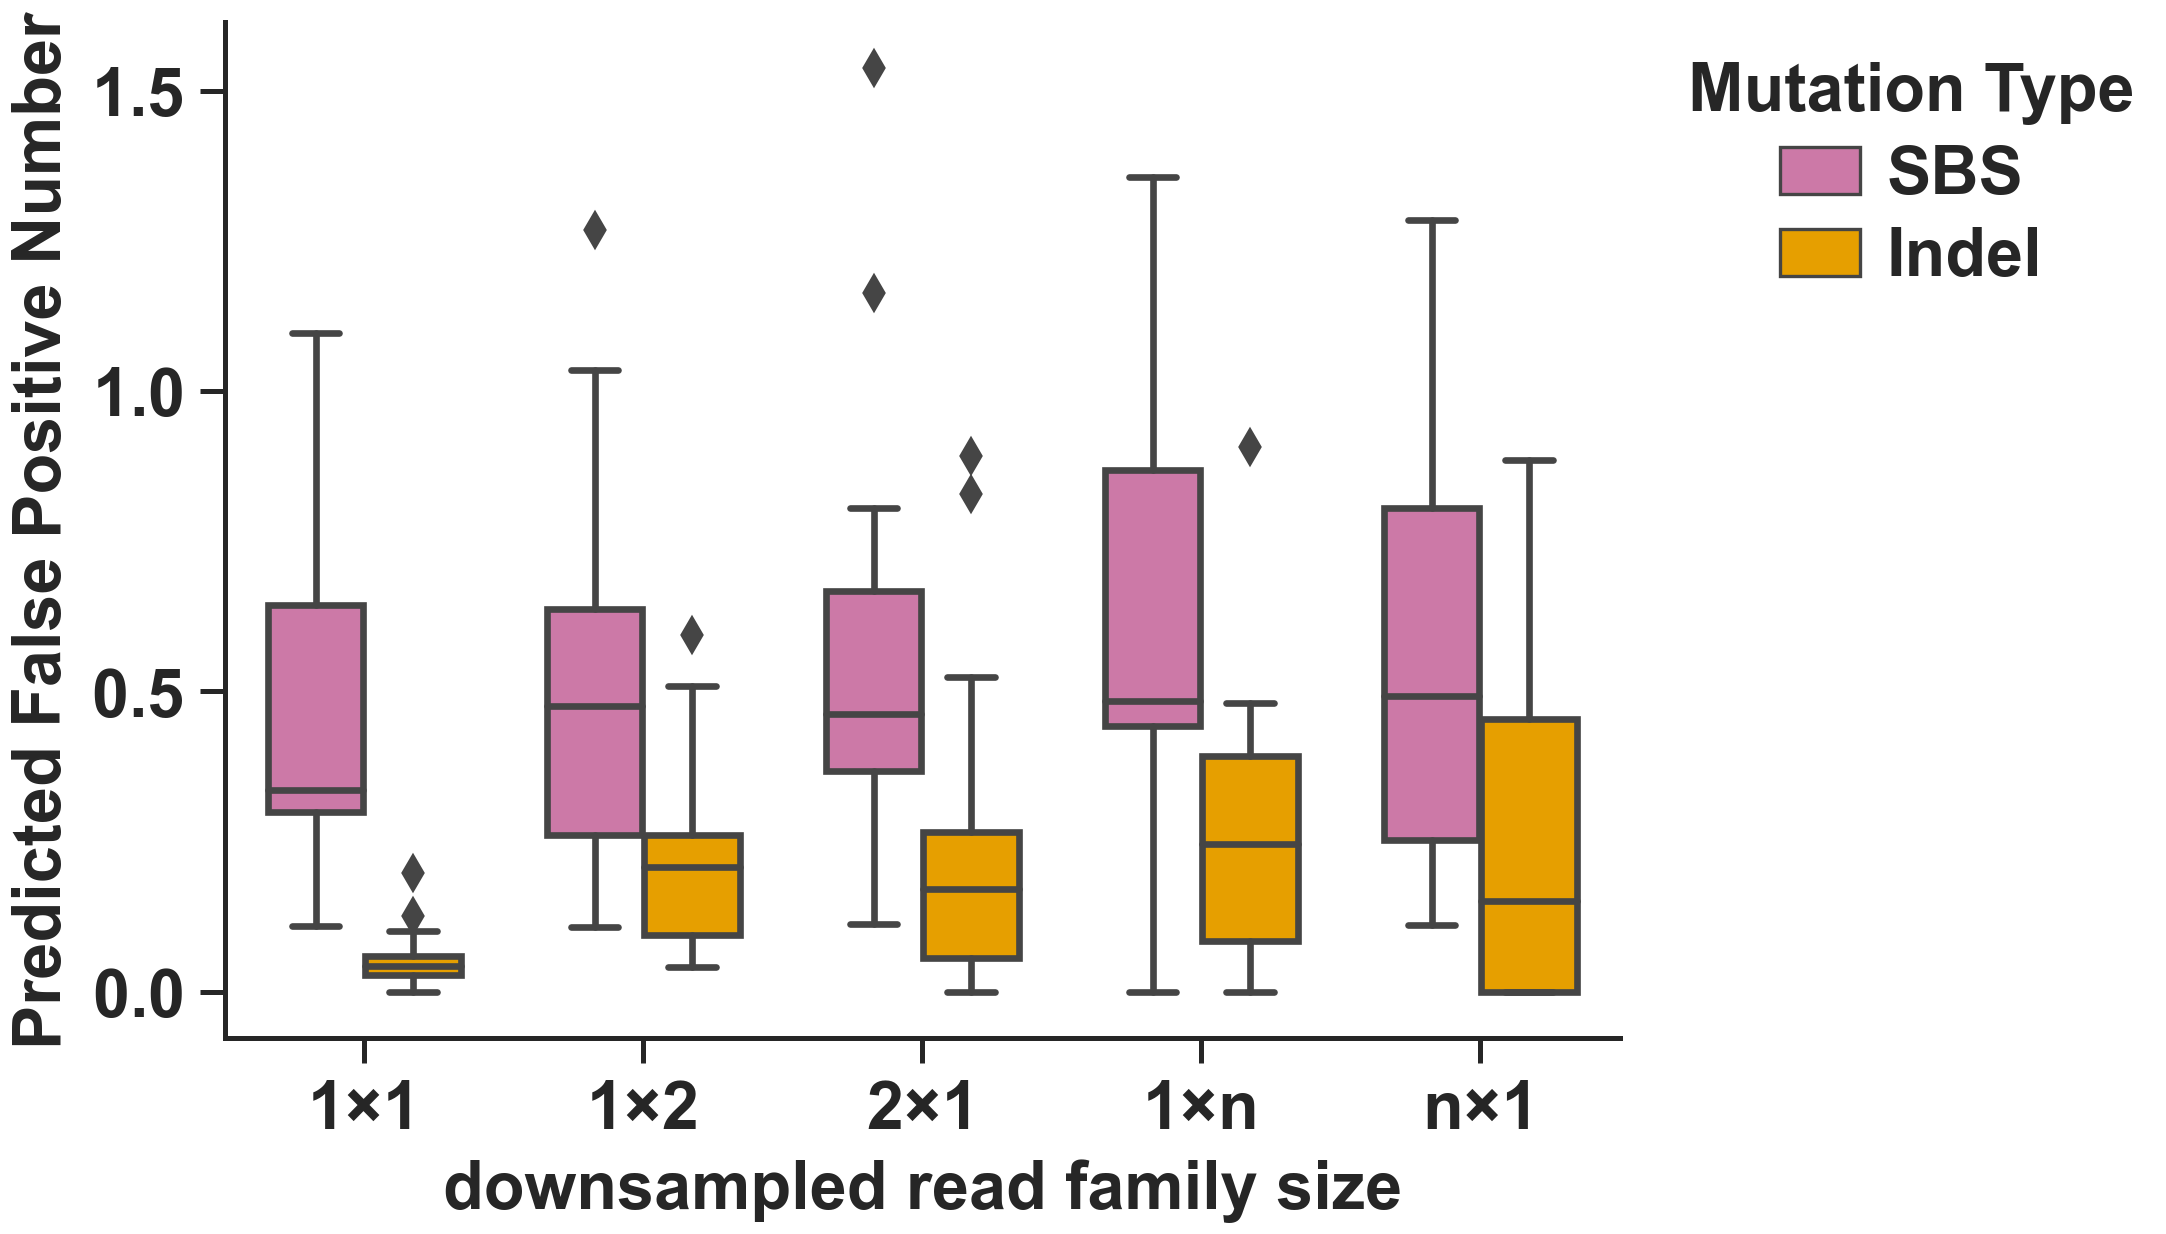

In [56]:
# Figure 2c — predicted false positive number per configuration per neuron
# Average the three downsampling seeds within each neuron/configuration first.
category_to_coverage_col = {
    "1x1": "duplex coverage 1x1", "1x2": "Duplex coverage 1x2", "2x1": "duplex coverage 2x1",
    "1xn": "Duplex coverage 1xn", "nx1": "Duplex coverage nx1",
}
weak_calls_col = "calls_with_less_than_2_reads_on_at_least_one_strand"
sample_keys = ["biological sample", "mutation type"]
configuration_keys = sample_keys + ["downsampled read family size"]
# Coverage and weakly supported call counts must be constant across seeds/configurations.
constant_cols = list(category_to_coverage_col.values()) + [weak_calls_col]
assert df6.groupby(sample_keys)[constant_cols].nunique(dropna=False).eq(1).all().all()
assert df6[constant_cols + ["false positive rate per duplex base"]].notna().all().all()
# The neuron totals of weakly supported calls live in their own tab, not as summary rows in `downsampling`.
if "downsampling_totals" in data:
    _weak_totals = data["downsampling_totals"].set_index("mutation type")[f"total {weak_calls_col}"]
    _weak_sums = df6.groupby(sample_keys)[weak_calls_col].first().groupby("mutation type").sum()
    assert _weak_sums.sort_index().eq(_weak_totals.sort_index()).all(), (_weak_sums, _weak_totals)
fp_rate_mean = df6.groupby(configuration_keys)["false positive rate per duplex base"].mean()
coverage_per_sample = df6.groupby(sample_keys)[constant_cols].first()
predicted_fp_configuration_df = fp_rate_mean.rename("mean false positive rate per duplex base").reset_index()
predicted_fp_configuration_df["predicted false positive number"] = [
    row["mean false positive rate per duplex base"] * coverage_per_sample.loc[
        (row["biological sample"], row["mutation type"]),
        category_to_coverage_col[row["downsampled read family size"]]]
    for _, row in predicted_fp_configuration_df.iterrows()
]
assert predicted_fp_configuration_df.groupby(["mutation type", "downsampled read family size"]).size().eq(17).all()
predicted_fp_configuration_plot = predicted_fp_configuration_df.assign(**{
    "downsampled read family size": predicted_fp_configuration_df["downsampled read family size"].map(FAMILY_LABEL),
    "mutation type": predicted_fp_configuration_df["mutation type"].map(MUTTYPE_LABEL),
})
FP_PER_NEURON_LABEL = "Predicted Additional False-Positive\nCalls Per Neuron Sample"   # Fig 2c and 2d y-axis
DOT_KW = dict(color="0.15", size=3, alpha=0.7, linewidth=0, zorder=4)            # individual neurons over the boxes
set_style(theme=True)
fig, ax = plt.subplots(figsize=(3.0, 2.2))
# Configurations of the naturally occurring read families in the original neurons (not downsampled data).
# Boxes and dots share seaborn's default dodge width (0.8) so each strip sits on its box.
c_kw = dict(data=predicted_fp_configuration_plot, x="downsampled read family size", y="predicted false positive number",
            hue="mutation type", order=FAMILY_LABEL_ORDER, hue_order=MUTTYPE_ORDER, ax=ax)
sns.boxplot(**c_kw, palette=MUTTYPE_PALETTE, saturation=1, width=.8, linewidth=.8, showfliers=False)
sns.stripplot(**c_kw, palette={m: DOT_KW["color"] for m in MUTTYPE_ORDER}, dodge=True, jitter=0.08,
              legend=False, **{k: v for k, v in DOT_KW.items() if k != "color"})
ax.set_xlabel("Read-Family Configuration")
ax.set_ylabel(FP_PER_NEURON_LABEL)
sns.move_legend(ax, "upper right", title="Mutation Type")
boldify(fig)
save(fig, "Figure2c.png")


               count    median      mean      std
mutation type                                    
indel             17  0.761683  1.022418  0.88048
sbs               17  2.357591  2.684538  1.26897
saved DupCaller_manuscript_plots/Figure2d.png


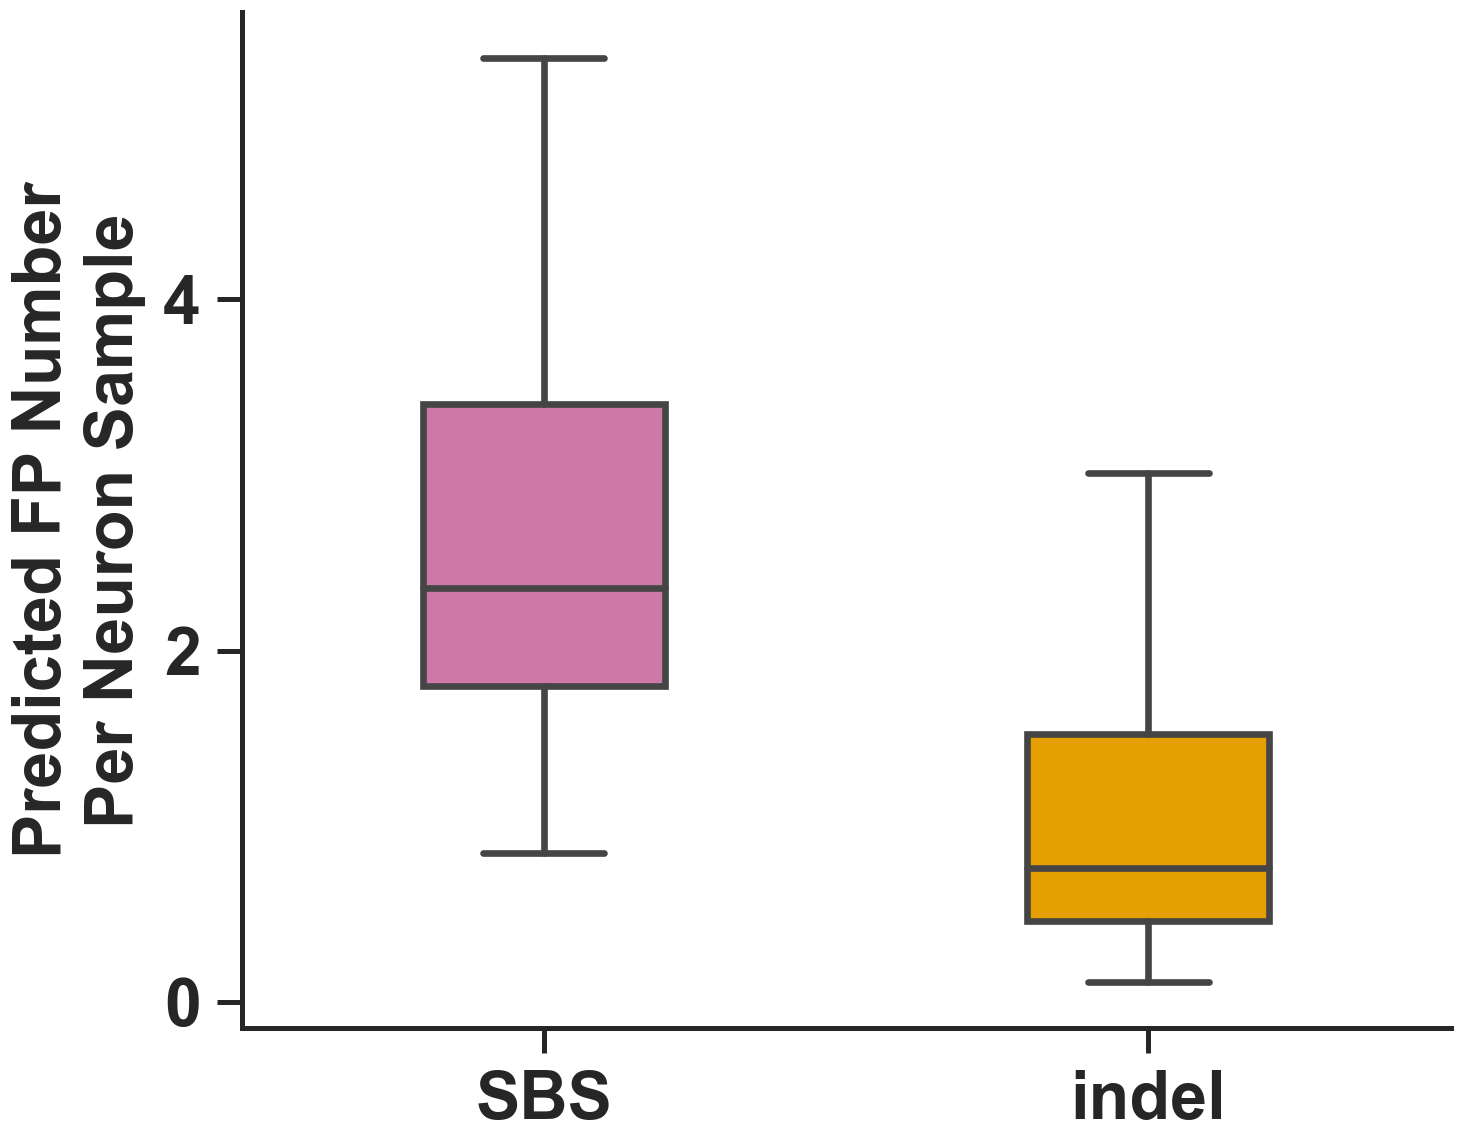

In [57]:
# Figure 2d — predicted FP number per neuron sample
# Sum predicted FP numbers over the five configurations for each neuron,
# plotted separately for SBS and indel (17 neurons each).
predicted_fp_df = predicted_fp_configuration_df.groupby(sample_keys)["predicted false positive number"].sum().to_frame()
predicted_fp_df = predicted_fp_df.join(coverage_per_sample[[weak_calls_col]]).reset_index()
assert predicted_fp_df[weak_calls_col].gt(0).all()
predicted_fp_df["predicted false positive rate"] = (
    predicted_fp_df["predicted false positive number"] / predicted_fp_df[weak_calls_col]
)
assert predicted_fp_df.groupby("mutation type")["biological sample"].nunique().eq(17).all()
assert predicted_fp_df.groupby("mutation type").size().eq(17).all()
print(predicted_fp_df.groupby("mutation type")["predicted false positive number"].agg(["count", "median", "mean", "std"]))
predicted_fp_plot = predicted_fp_df.assign(**{"mutation type": predicted_fp_df["mutation type"].map(MUTTYPE_LABEL)})
set_style(theme=True)
fig, ax = plt.subplots(figsize=(2.6, 2.2))
d_kw = dict(data=predicted_fp_plot, x="mutation type", y="predicted false positive number", order=MUTTYPE_ORDER, ax=ax)
# hue = x only to colour the boxes; no legend (the x-axis already names SBS / indel)
sns.boxplot(**d_kw, hue="mutation type", hue_order=MUTTYPE_ORDER, legend=False,
            palette=MUTTYPE_PALETTE, saturation=1, width=.4, linewidth=.8, showfliers=False)
sns.stripplot(**d_kw, jitter=0.08, **DOT_KW)
# The text reports means (boxes show medians): mark them with a diamond
fp_means = predicted_fp_plot.groupby("mutation type")["predicted false positive number"].mean().reindex(MUTTYPE_ORDER)
ax.scatter(range(len(fp_means)), fp_means.values, marker="D", s=16, facecolor="white", edgecolor="black",
           linewidth=0.8, zorder=5)
ax.legend([Line2D([], [], linestyle="none", marker="D", markersize=4, markerfacecolor="white",
                  markeredgecolor="black", markeredgewidth=0.8)], ["Mean"], loc="upper right")
ax.set_xlabel("")
ax.set_ylabel(FP_PER_NEURON_LABEL)
boldify(fig)
save(fig, "Figure2d.png")


## Figure 3 — Aristolochic acid exposure (AA_neuron_cordblood)
3a schematic, 3b/3e signatures and 3d/3g spectra and supplementary S2a, S5 (spectra) and S7 are not generated here.

In [58]:
def aa_bar(values, hue_labels, ylabel, fname):
    n = len(AA_LABELS)
    d = pd.DataFrame({"Sample": AA_LABELS * len(values),
                      "value": pd.concat(values, ignore_index=True),
                      "group": np.repeat(hue_labels, n)})
    fig, ax = plt.subplots(figsize=(2.2, 2.0))
    sns.barplot(ax=ax, data=d, x="Sample", y="value", hue="group", palette="Set1", width=.5)
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1.0, 1.0), title='', frameon=False)
    vmax = d["value"].max()
    if vmax >= 100:                                    # counts: single-digit ticks with ×10ⁿ on top (×10⁴ SBS, ×10² indel)
        exp = int(np.floor(np.log10(vmax)))
        ax.ticklabel_format(axis="y", style="sci", scilimits=(exp, exp), useMathText=True)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("")
    boldify(fig)
    save(fig, fname)

CLASSES = ["DupCaller only", "NanoSeq Software only", "Detected by both tools"]
METHODS = ["DupCaller", "NanoSeq Software"]
set_style(theme=True)
aa = COHORTS_AA
# Figure 3c
aa_bar([aa["DupCaller_only_SBS"], aa["NanoSeqSoftware_only_SBS"], aa["shared_SBS"]], CLASSES, "Total SBS count", "Figure3c_SBS_count.png")
aa_bar([aa["DupCaller_corrected_SBS_burden"], aa["NanoSeqSoftware_corrected_SBS_burden"]], METHODS, "SBS mutation burden", "Figure3c_SBS_burden.png")
# Figure 3f
aa_bar([aa["DupCaller_only_indel"], aa["NanoSeqSoftware_only_indel"], aa["shared_indel"]], CLASSES, "Total indel count", "Figure3f_indel_count.png")
aa_bar([aa["DupCaller_indel_uncorrected_burden"], aa["NanoSeqSoftware_indel_burden"]], METHODS, "indel mutation burden", "Figure3f_indel_burden.png")

saved DupCaller_manuscript_plots/Figure3c_SBS_count.png
saved DupCaller_manuscript_plots/Figure3c_SBS_burden.png
saved DupCaller_manuscript_plots/Figure3f_indel_count.png
saved DupCaller_manuscript_plots/Figure3f_indel_burden.png


In [59]:
def shared_proportion_plot(xcol, ycol, kind, text_y, text_size, fname):
    set_style(theme=True)
    fig, ax = plt.subplots(figsize=(2.6, 2.6))
    sns.scatterplot(data=COHORTS_noAA, x=xcol, y=ycol, hue='cohort', s=12, palette="Set1", legend="full", clip_on=False, ax=ax)
    ax.plot([0, 1], [0, 1], linestyle="dashed")
    ax.set_xlim([0, 1]); ax.set_ylim([0, 1])
    ax.set_xticks([0, 0.5, 1]); ax.set_yticks([0, 0.5, 1])
    ax.text(x=0.02, y=text_y, s="DupCaller\ncalls more", size=text_size, va="top")
    ax.text(x=0.98, y=0.04, s="NanoSeq Software\ncalls more", size=text_size, ha="right", va="bottom")
    ax.get_legend().remove()
    ax.set_xlabel(f"Proportion of shared {kind} (DupCaller)")
    ax.set_ylabel(f"Proportion of shared {kind}\n(NanoSeq Software)")
    boldify(fig)
    fig.tight_layout()
    save(fig, fname)


def burden_scatter(xcol, ycol, lim, kind, fname, legend_fname=None):
    set_style(theme=True)
    d = COHORTS_noAA.assign(cohort=COHORTS_noAA["cohort"].map(strip_n))
    fig, ax = plt.subplots(figsize=(2.4, 2.4))
    sns.scatterplot(data=d, x=xcol, y=ycol, s=12, hue="cohort", palette="Set1", ax=ax)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.plot([0, 6e-7], [0, 6e-7], '--')
    ax.set_ylabel(f"DupCaller {kind} burden")
    ax.set_xlabel(f"NanoSeq Software {kind} burden")
    ax.set_xscale('log'); ax.set_yscale('log')
    sns.move_legend(ax, "center right")
    boldify(fig)
    save(fig, fname)


def cordblood_bar(burdens, err_low, err_high, ylabel, fname):
    set_style(theme=True)
    methods = ["DupCaller", "NanoSeq\nSoftware", "Standard WGS\n(Abascal et al.)"]
    fig, ax = plt.subplots(figsize=(3.2, 2.0))
    ax.bar(methods, burdens, yerr=[err_low, err_high], capsize=3, color=sns.color_palette("Set1"), width=0.25)
    ax.set_ylabel(ylabel)
    fig.tight_layout()
    boldify(fig)
    save(fig, fname)

cb = COHORTS[COHORTS["Sample"].isin(CORDBLOOD_SAMPLES)]

## Figure 4 — SBS comparison in neurons and cord blood (AA_neuron_cordblood)
4c spectra not generated.

In [60]:
# Figure 4a
shared_proportion_plot('DupCaller_shared_SBS_proportion', 'NanoSeqSoftware_shared_SBS_proportion', "SBSs", 0.8, 8, "Figure4a.png")
# Figure 4b
burden_scatter("NanoSeqSoftware_corrected_SBS_burden", "DupCaller_corrected_SBS_burden", [5e-9, 6e-7], "SBS", "Figure4b.png")

saved DupCaller_manuscript_plots/Figure4a.png
  legend moved to 'upper left' in Figure4b.png
saved DupCaller_manuscript_plots/Figure4b.png


In [61]:
# Figure 4d — cord blood SBS burden
# For each caller: corrected count = sum(calls x correction ratio) over the six PD48442 samples and all SBS96
# channels, 95% Fay–Feuer CI (Methods), divided by the pooled duplex coverage, then x 1/0.76 sensitivity factor.
def cordblood_sbs_burden(caller, coverage_col, table_col):
    tab = CORD_CI[(CORD_CI["Caller"] == caller) & CORD_CI["Sample"].isin(CORDBLOOD_SAMPLES)]
    y, lo, hi = fay_feuer_ci(tab["count"], tab["ratio"])
    cov = cb[coverage_col].sum()
    per_sample = tab.assign(w=tab["count"] * tab["ratio"]).groupby("Sample")["w"].sum()
    diff = (per_sample - cb.set_index("Sample")[table_col]).abs()
    if (diff > 1e-6).any():
        print(f"NOTE: {caller} corrected counts differ from AA_neuron_cordblood:{table_col} for "
              + ", ".join(f"{k} ({per_sample[k]:.2f} vs {cb.set_index('Sample').loc[k, table_col]:.2f})" for k in diff[diff > 1e-6].index))
    print(f"Fig 4d {caller}: {y / cov:.4g} per base (95% CI {lo / cov:.4g}-{hi / cov:.4g}) before x{SENSITIVITY_FACTOR}")
    return y / cov * SENSITIVITY_FACTOR, lo / cov * SENSITIVITY_FACTOR, hi / cov * SENSITIVITY_FACTOR

dc_burden, dc_low, dc_high = cordblood_sbs_burden("DupCaller", "DupCaller_SBS_coverage", "DupCaller_SBS_corrected_num")
nas_burden, nas_low, nas_high = cordblood_sbs_burden("NanoSeq Software", "NanoSeqSoftware_coverage", "NanoSeq_SBS_corrected_num")
# Standard WGS of cord-blood colonies (Abascal et al.): SBS burden per base and its reported interval
wgs_burden, wgs_low, wgs_high = 1.18e-8, 1.1e-8, 1.27e-8
cordblood_bar([dc_burden, nas_burden, wgs_burden],
              [dc_burden-dc_low, nas_burden-nas_low, wgs_burden-wgs_low],
              [dc_high-dc_burden, nas_high-nas_burden, wgs_high-wgs_burden],
              "SBS burden per base", "Figure4d.png")

Fig 4d DupCaller: 1.346e-08 per base (95% CI 1.213e-08-1.493e-08) before x1.32
Fig 4d NanoSeq Software: 1.438e-08 per base (95% CI 1.247e-08-1.654e-08) before x1.32
saved DupCaller_manuscript_plots/Figure4d.png


## Figure 5 — Indel comparison in neurons and cord blood (AA_neuron_cordblood)
5c spectra not generated.

In [62]:
# Figure 5a
shared_proportion_plot('DupCaller_shared_indel_proportion', 'NanoSeqSoftware_shared_indel_proportion', "indels", 0.8, 8, "Figure5a.png")
# Figure 5b
burden_scatter("NanoSeqSoftware_indel_burden", "DupCaller_indel_uncorrected_burden", [2e-10, 6e-8], "Indel", "Figure5b.png")

saved DupCaller_manuscript_plots/Figure5a.png
  legend moved to 'upper left' in Figure5b.png
saved DupCaller_manuscript_plots/Figure5b.png


In [63]:
# Figure 5d — cord blood indel burden (Poisson CIs)
dc_count = (cb["DupCaller_only_indel"] + cb["shared_indel"]).sum()
dc_cov = cb["DupCaller_indel_coverage"].sum()
nas_count = (cb["NanoSeqSoftware_only_indel"] + cb["shared_indel"]).sum()
nas_cov = cb["NanoSeqSoftware_coverage"].sum()
dc_burden = dc_count / dc_cov * SENSITIVITY_FACTOR
nas_burden = nas_count / nas_cov * SENSITIVITY_FACTOR
dc_low, dc_high = (c / dc_cov * SENSITIVITY_FACTOR for c in poisson_ci(dc_count))
nas_low, nas_high = (c / nas_cov * SENSITIVITY_FACTOR for c in poisson_ci(nas_count))

# Standard WGS of cord-blood colonies (Abascal et al.): indel burden per base and its reported interval
wgs_burden, wgs_low, wgs_high = 6.5e-10, 4.8e-10, 8.7e-10
cordblood_bar([dc_burden, nas_burden, wgs_burden],
              [dc_burden-dc_low, nas_burden-nas_low, wgs_burden-wgs_low],
              [dc_high-dc_burden, nas_high-nas_burden, wgs_high-wgs_burden],
              "indel burden per base", "Figure5d.png")

saved DupCaller_manuscript_plots/Figure5d.png


## Figure 6 — Sperm, blood and saliva (sperm_blood_saliva)
6c/6d spectra not generated.

In [64]:
colors = sns.color_palette("Set1")[0:3]
TISSUE_LEGEND_SIZE = 6.5   # compact legend shared by 6a and 6b so it covers no dots


def tissue_legend(ax, loc):
    """Framed tissue legend inside the axes: small markers, tight spacing (text shrunk by shrink_tissue_legend)."""
    handles = [Line2D([], [], linestyle="none", marker="o", markersize=3, markerfacecolor=c, markeredgecolor=c) for c in colors]
    ax.legend(handles, TISSUE_LABELS, title="Tissue", loc=loc,
              borderpad=0.25, labelspacing=0.15, handletextpad=0.1, borderaxespad=0.2)


def shrink_tissue_legend(ax):
    """Call after boldify (which resets legend text to FONT_SIZE)."""
    for t in ax.get_legend().get_texts() + [ax.get_legend().get_title()]:
        t.set_fontsize(TISSUE_LEGEND_SIZE)


# Figure 6a
set_style(theme=True)
fig, ax = plt.subplots(figsize=(2.6, 2.6))
sns.scatterplot(data=SPERM, x="nanoseqsoftware_SBS_corrected_burden", y="DupCaller_SBS_corrected_burden",
                s=12, hue="Tissue", hue_order=["Sperm", "Blood", "Saliva"], palette="Set1", ax=ax)
ax.set_aspect('equal', adjustable='box')
ax.set_xlim([5e-9, 4e-7]); ax.set_ylim([5e-9, 4e-7])
ax.plot([0, 6e-7], [0, 6e-7], '--')
ax.set_ylabel("DupCaller SBS burden")
ax.set_xlabel("NanoSeq Software SBS burden")
ax.set_xscale('log'); ax.set_yscale('log')
tissue_legend(ax, "upper left")
boldify(fig)
shrink_tissue_legend(ax)
save(fig, "Figure6a.png")

# Figure 6b
set_style(theme=True)
fig, ax = plt.subplots(figsize=(2.6, 2.6))   # same size as Fig 6a
sns.scatterplot(data=SPERM, y="DupCaller_NanoSeq_SBS_ratio", x="Duplication_Rate",
                hue="Tissue", hue_order=["Sperm", "Blood", "Saliva"], palette="Set1", s=12, ax=ax)
ax.set_box_aspect(1)   # square plot area (equal x and y length), like Fig 6a
ax.set_xlabel("Duplication rate")
ax.set_ylabel("DupCaller/NanoSeq Software\nSBS ratio")
# y-axis starts below 1 with a reference line at 1 (no gain), so the gain at high duplication stays visible
ax.axhline(1, color="0.5", linestyle="--", linewidth=0.6, zorder=0)
# top at 2.1 (data max ~1.93) leaves the upper-right corner of the square plot free for the legend
ax.set_ylim(0.9, max(2.1, SPERM["DupCaller_NanoSeq_SBS_ratio"].max() * 1.09))
ax.yaxis.set_major_locator(mticker.MultipleLocator(0.25))
tissue_legend(ax, "upper right")
plt.tight_layout()
boldify(fig)
shrink_tissue_legend(ax)
save(fig, "Figure6b.png")

  legend moved to 'upper left' in Figure6a.png
saved DupCaller_manuscript_plots/Figure6a.png
saved DupCaller_manuscript_plots/Figure6b.png


## Supplementary figures (supplementary_figures_v8)
Saved under `DupCaller_manuscript_plots/Supplementary/`.
S2a (schematic), S5 (cord blood spectra) and S7 (model) are not drawn in Python.

In [65]:
def pr_grid(kind, xlsx, mutlevels, xlim, title_unit, fname):
    """5x5 precision–recall curves for the synthetic datasets (rows = mutation count, columns = replicate).
    The shared legend sits above the grid in the manuscript; it is saved separately (FigureS1_S3_legend.svg)."""
    if not os.path.exists(xlsx):
        print(f"SKIPPED {fname}: {xlsx} not found")
        return
    samples = [f"{kind}_n{b}_rep{a}" for a, b in itertools.product(range(1, 6), mutlevels)]
    nas = pd.read_excel(xlsx, "NanoSeq_Software_v3.5.5", engine="openpyxl").rename(columns={"Dataset": "Sample"})
    nas["mutnum"] = nas["TP"] + nas["FN"]
    fig, ax = plt.subplots(5, 5, figsize=(7.0, 7.0))
    for nn, sample in enumerate(samples):
        col, row = nn // 5, nn % 5
        pr = pd.read_excel(xlsx, sample, engine='openpyxl')
        start = np.searchsorted(pr["thr"], 0)
        # default operating point: last threshold with lFDR <= 0.05 (inclusive); -1 if no call passes
        thr = np.searchsorted(pr["thr"], 0.05, side="right") - 1
        a = ax[row, col]
        if thr >= 0:
            a.scatter(pr.loc[thr, "recall"], pr.loc[thr, "precision"], facecolors='none', edgecolor='r', s=18, linewidths=0.8)
        else:
            print(f"NOTE: {sample} - no calls with lFDR <= 0.05; default operating point not drawn")
        a.plot(pr.loc[start:, "recall"], pr.loc[start:, "precision"], color="r", linewidth=0.6)
        s_nas = nas[nas["Sample"] == sample]
        a.scatter(s_nas["recall"], s_nas["precision"], marker='^', color='b', s=14, linewidths=0)
        a.set_xlim(xlim); a.set_ylim([0, 1.05])
        a.set_xticks([0, xlim[1] / 2, xlim[1]] if xlim[1] < 1 else [0, 0.5, 1]); a.set_yticks([0, 0.5, 1])
        a.set_title(f"n={int(s_nas['mutnum'].values[0])} {title_unit}")
        a.set_xlabel("recall")
        a.set_ylabel("precision")
    fig.tight_layout()
    boldify(fig, max_ticks=3)
    save(fig, fname, supp=True)


def pr_legend(fname):
    fig, ax = plt.subplots(figsize=(4, 0.3))
    handles = [Line2D([0], [0], color='r', lw=1),
               Line2D([], [], linestyle="none", marker=mmark.MarkerStyle("o", fillstyle="none"), markeredgecolor='r', markeredgewidth=0.8, markersize=5),
               Line2D([], [], linestyle="none", marker="^", markerfacecolor='b', markeredgecolor='b', markersize=5)]
    ax.legend(handles, [legend_case(x) for x in ["DupCaller", "DupCaller (default)", "NanoSeq Software"]], loc="center", ncol=3, frameon=False, prop={"weight": "bold", "size": FONT_SIZE})
    ax.axis("off")
    fig.savefig(os.path.join(SUPP_DIR, fname), bbox_inches="tight")
    print("saved", os.path.relpath(os.path.join(SUPP_DIR, fname), ROOT))
    plt.close(fig)

### Figure S1 — SBS precision–recall curves on synthetic datasets

In [66]:
if MAKE_SUPPLEMENTARY:
    set_style(theme=True)          # same open-axes style as Fig S3 (no top/right border)
    pr_grid("SBS", SYNTH_SBS_XLSX, ["100", "500", "1000", "2000", "5000"], [0, 0.8], "SBSs", "FigureS1.png")
    pr_legend("FigureS1_S3_legend.svg")

ValueError: Worksheet named 'NanoSeq_Software_v3.5.5' not found

### Figure S2b/c — Precision, recall and F1 score vs mutation number (synthetic_SBS_summary / synthetic_indel_summary)
Line plots (mean ± SD across the 5 replicates per mutation count). Uncorrected precision and F1, as in v8.
The legend is drawn only on the F1 panel, as in the manuscript.

In [ ]:
def benchmark_long(table):
    t = table.dropna(subset=["Mutation number"]).copy()
    t["Mutation number"] = t["Mutation number"].astype(int)
    out = []
    for caller, p in [("DupCaller", "DupCaller"), ("NanoSeq Software", "NanoSeq")]:
        out.append(pd.DataFrame({
            "Mutation number": t["Mutation number"], "Caller": caller,
            "Precision": t[f"{p}_Precision"],
            "Recall": t[f"{p}_Recall"],
            "F1 score": 2/(1/t[f"{p}_Recall"] + 1/t[f"{p}_Precision"]),
        }))
    return pd.concat(out, ignore_index=True)


CALLER_PALETTE = {"DupCaller": sns.color_palette("Set1")[0], "NanoSeq Software": sns.color_palette("Set1")[1]}   # red / blue, as in Fig S1 and the main figures


def benchmark_line(long_df, metric, fname, show_legend):
    set_style(theme=True)
    fig, ax = plt.subplots(figsize=(2.2, 2.0))
    sns.lineplot(data=long_df, x="Mutation number", y=metric, hue="Caller", hue_order=["DupCaller", "NanoSeq Software"],
                 palette=CALLER_PALETTE, ax=ax, errorbar="sd", err_style="bars", marker="o")
    ax.set_ylim([0, 1])
    if show_legend:
        sns.move_legend(ax, "lower right")
    else:
        ax.get_legend().remove()
    boldify(fig)
    save(fig, fname, supp=True)


if MAKE_SUPPLEMENTARY:
    for panel, table in [("S2b", SYNTH_SBS), ("S2c", SYNTH_INDEL)]:      # b = SBS (synthetic_SBS_summary), c = indel (synthetic_indel_summary)
        long_df = benchmark_long(table)
        for metric, tag in [("Precision", "precision"), ("Recall", "recall"), ("F1 score", "F1")]:
            benchmark_line(long_df, metric, f"Figure{panel}_{tag}.png", show_legend=(metric == "F1 score"))

saved DupCaller_manuscript_plots/Supplementary/FigureS2b_precision.png
saved DupCaller_manuscript_plots/Supplementary/FigureS2b_recall.png
saved DupCaller_manuscript_plots/Supplementary/FigureS2b_F1.png
saved DupCaller_manuscript_plots/Supplementary/FigureS2c_precision.png
saved DupCaller_manuscript_plots/Supplementary/FigureS2c_recall.png
saved DupCaller_manuscript_plots/Supplementary/FigureS2c_F1.png


### Figure S3 — indel precision–recall curves on synthetic datasets

In [ ]:
if MAKE_SUPPLEMENTARY:
    set_style(theme=True)
    pr_grid("indel", SYNTH_INDEL_XLSX, ["10", "50", "100", "200", "500"], [0, 1.05], "Indels", "FigureS3.png")

saved DupCaller_manuscript_plots/Supplementary/FigureS3.png


### Figure S4 — Duplication rate vs DupCaller/NanoSeq SBS ratio (AA_neuron_cordblood)

saved DupCaller_manuscript_plots/Supplementary/FigureS4.png


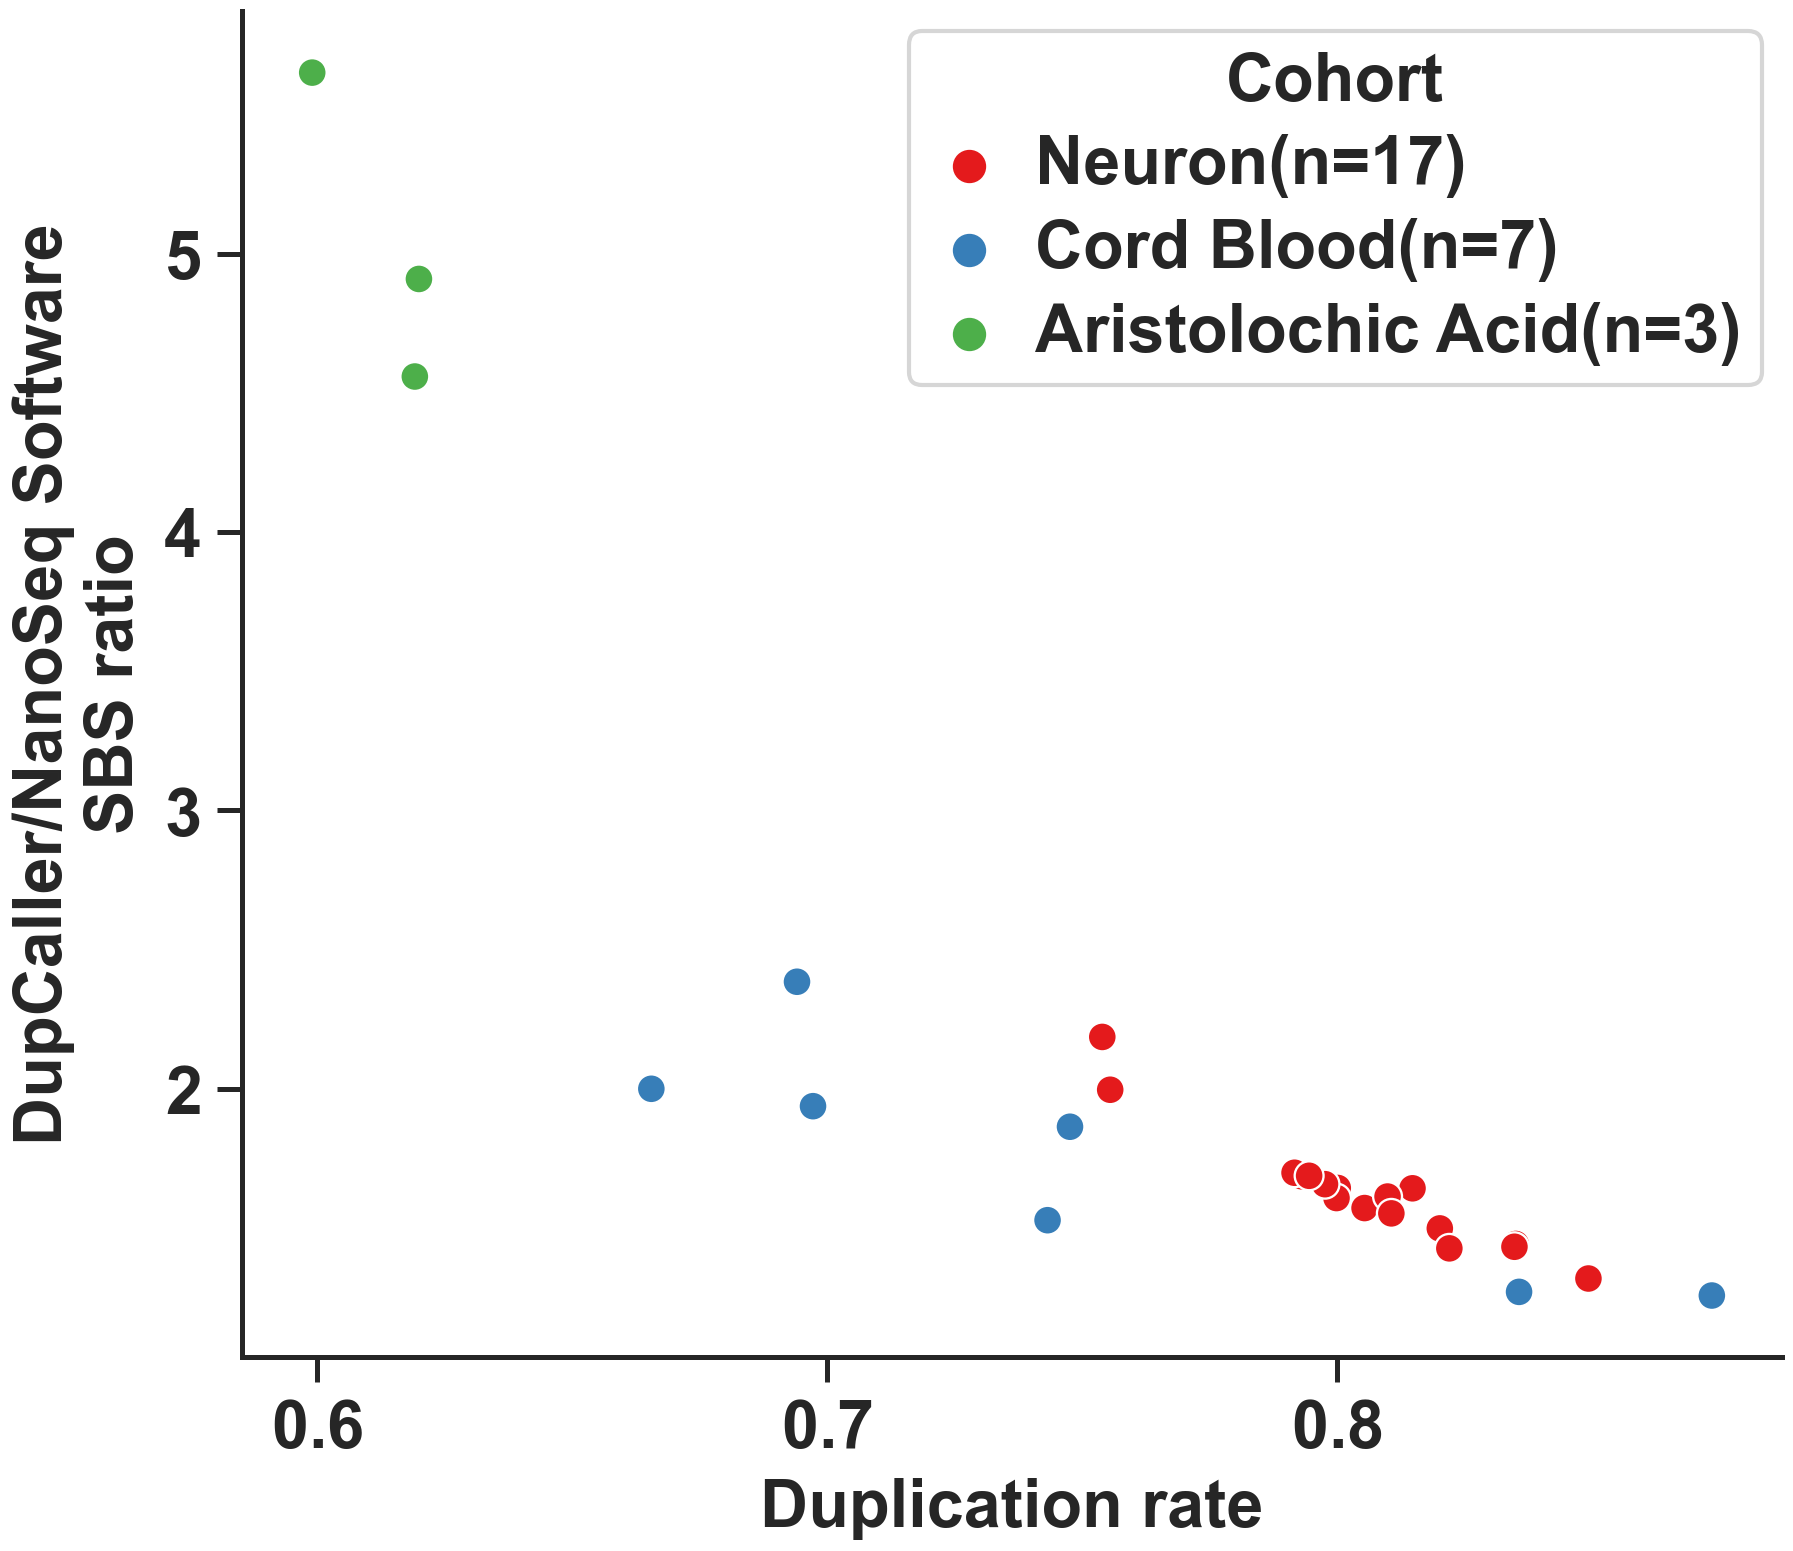

In [ ]:
if MAKE_SUPPLEMENTARY:
    set_style(theme=True)
    fig, ax = plt.subplots(figsize=(3.2, 2.8))
    sns.scatterplot(data=COHORTS, y="DupCaller_NanoSeq_SBS_ratio", x="Duplication_Rate", hue="cohort", palette="Set1",
                    hue_order=["Neuron (n=17)", "Cord blood (n=7)", "Aristolochic acid (n=3)"], s=12, ax=ax)
    ax.set_xlabel("Duplication rate")
    ax.set_ylabel("DupCaller/NanoSeq Software\nSBS ratio")
    # y-axis starts below 1 with a reference line at 1 (no gain), so the gain at high duplication stays visible
    ax.axhline(1, color="0.5", linestyle="--", linewidth=0.6, zorder=0)
    ax.set_ylim(0.8, COHORTS["DupCaller_NanoSeq_SBS_ratio"].max() * 1.05)
    ax.yaxis.set_major_locator(mticker.MultipleLocator(1))
    sns.move_legend(ax, "upper right")
    plt.tight_layout()
    boldify(fig)
    save(fig, "FigureS4.png", supp=True)

### Figure S6 — Computation time (runtime)

In [ ]:
if MAKE_SUPPLEMENTARY:
    set_style(theme=False)
    fig, ax = plt.subplots(figsize=(4.0, 2.4))
    sns.barplot(data=RUNTIME, x="step", y="hours", hue="method", palette="Set1", order=["trim", "bwa", "mkdp", "tag", "call", "total"], errorbar="sd", ax=ax)   # legend: mean ± SD
    ax.set_ylabel("Time(Hour)")
    ax.set_xticks(ticks=ax.get_xticks(), labels=["trim(cpu=1)", "bwa(cpu=64)", "mkdp(cpu=16)", "tag(cpu=1)", "call(cpu=64)", "total"], rotation=30, ha="right")
    boldify(fig)
    save(fig, "FigureS6.png", supp=True)

saved DupCaller_manuscript_plots/Supplementary/FigureS6.png


## SBS96 cosine similarities (source_data_spectra/DupCaller_SBS96_ID83_spectra.xlsx, tab SBS96)
Cosine similarity of SBS96 spectra, with a 95% interval from multinomial resampling (2.5th–97.5th percentile).
- **Spectrum vs reference signature** (AA calls vs COSMIC v3.5 SBS22a; sperm DupCaller calls vs the parental de novo reference from deCODE trios): only the observed counts are resampled.
- **2×2+ vs 2×2− read-support strata** (AA, neuron, sperm): both count vectors are resampled independently and each replicate pair is compared.

Same method, comparisons, replicate numbers and seed (20261119) as `data/source_data_spectra/calculate_cosine_similarity.py`, so the table matches `SBS96_cosine_similarity.csv`. Writes `DupCaller_manuscript_plots/SBS96_cosine_similarity.csv`.

In [ ]:
COSINE_SEED = 20261119
COSINE_COMPARISONS = [   # (spectrum, reference, replicates, resample both vectors)
    ("AA_DupCaller_only", "COSMIC_v3.5_SBS22a (proportion)", 10000, False),
    ("AA_NanoSeq_only", "COSMIC_v3.5_SBS22a (proportion)", 10000, False),
    ("AA_both", "COSMIC_v3.5_SBS22a (proportion)", 10000, False),
    ("Sperm_DupCaller", "Parental_de_novo_reference (decode trios)", 300000, False),
    ("AA_2x2+", "AA_2x2-", 100000, True),
    ("Neuron_2x2+", "Neuron_2x2-", 100000, True),
    ("Sperm_2x2+", "Sperm_2x2-", 100000, True),
]


def cosine_with_interval(a, b, repeats, both, rng, batch=10000):
    """Observed cosine of a and b, plus the 2.5/50/97.5 percentiles of the cosine after multinomial resampling of
    a (and of b too when both=True). Batches only bound memory; they draw the same numbers as one big draw."""
    assert np.isfinite(a).all() and np.isfinite(b).all()
    assert (a >= 0).all() and (b >= 0).all() and a.sum() > 0 and b.sum() > 0
    assert np.array_equal(a, a.astype(np.int64)), "resampled spectrum must be integer counts"
    if both:
        assert np.array_equal(b, b.astype(np.int64))
    observed = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    sims = []
    for start in range(0, repeats, batch):
        n = min(batch, repeats - start)
        ra = rng.multinomial(int(a.sum()), a / a.sum(), size=n)
        rb = rng.multinomial(int(b.sum()), b / b.sum(), size=n) if both else b
        dot = (ra * rb).sum(axis=1) if both else ra @ rb
        norm_b = np.linalg.norm(rb, axis=1) if both else np.linalg.norm(rb)
        sims.append(dot / (np.linalg.norm(ra, axis=1) * norm_b))
    low, median, high = np.percentile(np.concatenate(sims), [2.5, 50, 97.5])
    return observed, median, low, high


if not os.path.exists(SPECTRA_XLSX):
    print(f"SKIPPED SBS96 cosine similarities: {SPECTRA_XLSX} not found")
else:
    # row 1 = section labels, row 2 = column names, then the 96 channels
    SBS96 = pd.read_excel(SPECTRA_XLSX, "SBS96", header=1, index_col=0, engine="openpyxl")
    assert len(SBS96) == 96 and SBS96.index.is_unique
    rng = np.random.RandomState(COSINE_SEED)   # one stream, comparisons drawn in the order listed
    rows = []
    for spectrum, reference, repeats, both in COSINE_COMPARISONS:
        a = SBS96[spectrum].to_numpy(dtype=float)
        b = SBS96[reference].to_numpy(dtype=float)
        observed, median, low, high = cosine_with_interval(a, b, repeats, both, rng)
        rows.append(dict(spectrum=spectrum, reference=reference, observed_cosine=observed,
                         bootstrap_median=median, lower_2_5=low, upper_97_5=high,
                         n_spectrum=int(a.sum()), n_reference=float(b.sum()),
                         replicates=repeats, resample_both=both, seed=COSINE_SEED))
    COSINE_SBS96 = pd.DataFrame(rows)
    COSINE_SBS96.to_csv(os.path.join(OUT_DIR, "SBS96_cosine_similarity.csv"), index=False)
    for r in COSINE_SBS96.itertuples():
        print(f"{r.spectrum} vs {r.reference}: observed={r.observed_cosine:.4f}; "
              f"median={r.bootstrap_median:.4f}; 95% interval=[{r.lower_2_5:.4f}, {r.upper_97_5:.4f}]")
    print("Saved:", os.path.join(OUT_DIR, "SBS96_cosine_similarity.csv"))

In [ ]:
print("\nAll figures in", os.path.abspath(OUT_DIR))
for root, _, files in os.walk(OUT_DIR):
    for f in sorted(files):
        print(" ", os.path.join(root, f))


All figures in /Users/yuhecheng/Documents/Projects/DupCaller/round_1/DupCaller_figure_reproduction_1.2.13/DupCaller_manuscript_plots
  /Users/yuhecheng/Documents/Projects/DupCaller/round_1/DupCaller_figure_reproduction_1.2.13/DupCaller_manuscript_plots/.DS_Store
  /Users/yuhecheng/Documents/Projects/DupCaller/round_1/DupCaller_figure_reproduction_1.2.13/DupCaller_manuscript_plots/Figure2b_precision.png
  /Users/yuhecheng/Documents/Projects/DupCaller/round_1/DupCaller_figure_reproduction_1.2.13/DupCaller_manuscript_plots/Figure2b_recall.png
  /Users/yuhecheng/Documents/Projects/DupCaller/round_1/DupCaller_figure_reproduction_1.2.13/DupCaller_manuscript_plots/Figure2c.png
  /Users/yuhecheng/Documents/Projects/DupCaller/round_1/DupCaller_figure_reproduction_1.2.13/DupCaller_manuscript_plots/Figure2d.png
  /Users/yuhecheng/Documents/Projects/DupCaller/round_1/DupCaller_figure_reproduction_1.2.13/DupCaller_manuscript_plots/Figure3c_SBS_burden.png
  /Users/yuhecheng/Documents/Projects/DupCa